# 01 - Data Exploration

**Goal:** understand the California housing dataset *before* changing anything.

**Input:** `data/raw/housing.csv`  |  **Output:** observations and charts in `images/` (the data is not modified)

### Tasks in this notebook
- [x] Load the data and look at the first and last rows
- [x] Check shape, column names, and data types
- [x] Summary statistics
- [x] Missing values and duplicates
- [x] Count the categories in `ocean_proximity`
- [x] Histograms, map-style scatter plot, box plots, correlation heatmap, bar chart
- [x] Write down your observations

## 1. Setup and load the data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

DATA_PATH = Path('../data/raw/housing.csv')
IMAGE_DIR = Path('../images')
IMAGE_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH)
print('Loaded:', DATA_PATH)

Loaded: ../data/raw/housing.csv


## 2. First look
`head()` and `tail()` show the first and last rows. Look at the column names and the kind of values in each.

In [ ]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
df.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


## 3. Shape, data types, and structure

In [ ]:
print('Rows, columns:', df.shape)
print()
df.info()

Rows, columns: (20640, 10)

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


## 4. Summary statistics
`describe()` gives count, mean, std, min, quartiles, and max for every numeric column. Compare the **mean** with the **50%** (median): a big gap suggests skew.

In [ ]:
df.describe().round(2)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.00,20640.00,20640.00,20640.00,20433.00,20640.00,20640.00,20640.00,20640.00
mean,-119.57,35.63,28.64,2635.76,537.87,1425.48,499.54,3.87,206855.82
std,2.00,2.14,12.59,2181.62,421.39,1132.46,382.33,1.90,115395.62
min,-124.35,32.54,1.00,2.00,1.00,3.00,1.00,0.50,14999.00
25%,-121.80,33.93,18.00,1447.75,296.00,787.00,280.00,2.56,119600.00
50%,-118.49,34.26,29.00,2127.00,435.00,1166.00,409.00,3.53,179700.00
75%,-118.01,37.71,37.00,3148.00,647.00,1725.00,605.00,4.74,264725.00
max,-114.31,41.95,52.00,39320.00,6445.00,35682.00,6082.00,15.00,500001.00


## 5. Missing values and duplicates

In [ ]:
missing = df.isna().sum()
missing_pct = (df.isna().mean() * 100).round(2)
pd.DataFrame({'missing': missing, 'percent': missing_pct})

,missing,percent
longitude,0,0.0
latitude,0,0.0
housing_median_age,0,0.0
total_rooms,0,0.0
total_bedrooms,207,1.0
population,0,0.0
households,0,0.0
median_income,0,0.0
median_house_value,0,0.0
ocean_proximity,0,0.0


In [ ]:
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 0


## 6. The categorical column: `ocean_proximity`

In [ ]:
df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [ ]:
# Average house value for each category (groupby practice)
df.groupby('ocean_proximity')['median_house_value'].agg(['count', 'mean', 'median']).round(0)

,count,mean,median
ocean_proximity,,,
<1H OCEAN,9136,240084.0,214850.0
INLAND,6551,124805.0,108500.0
ISLAND,5,380440.0,414700.0
NEAR BAY,2290,259212.0,233800.0
NEAR OCEAN,2658,249434.0,229450.0


## 7. Visualizations

### 7.1 Histograms of every numeric column
Histograms show the *shape* of each feature. Many of these are strongly right-skewed (a long tail of very large values).

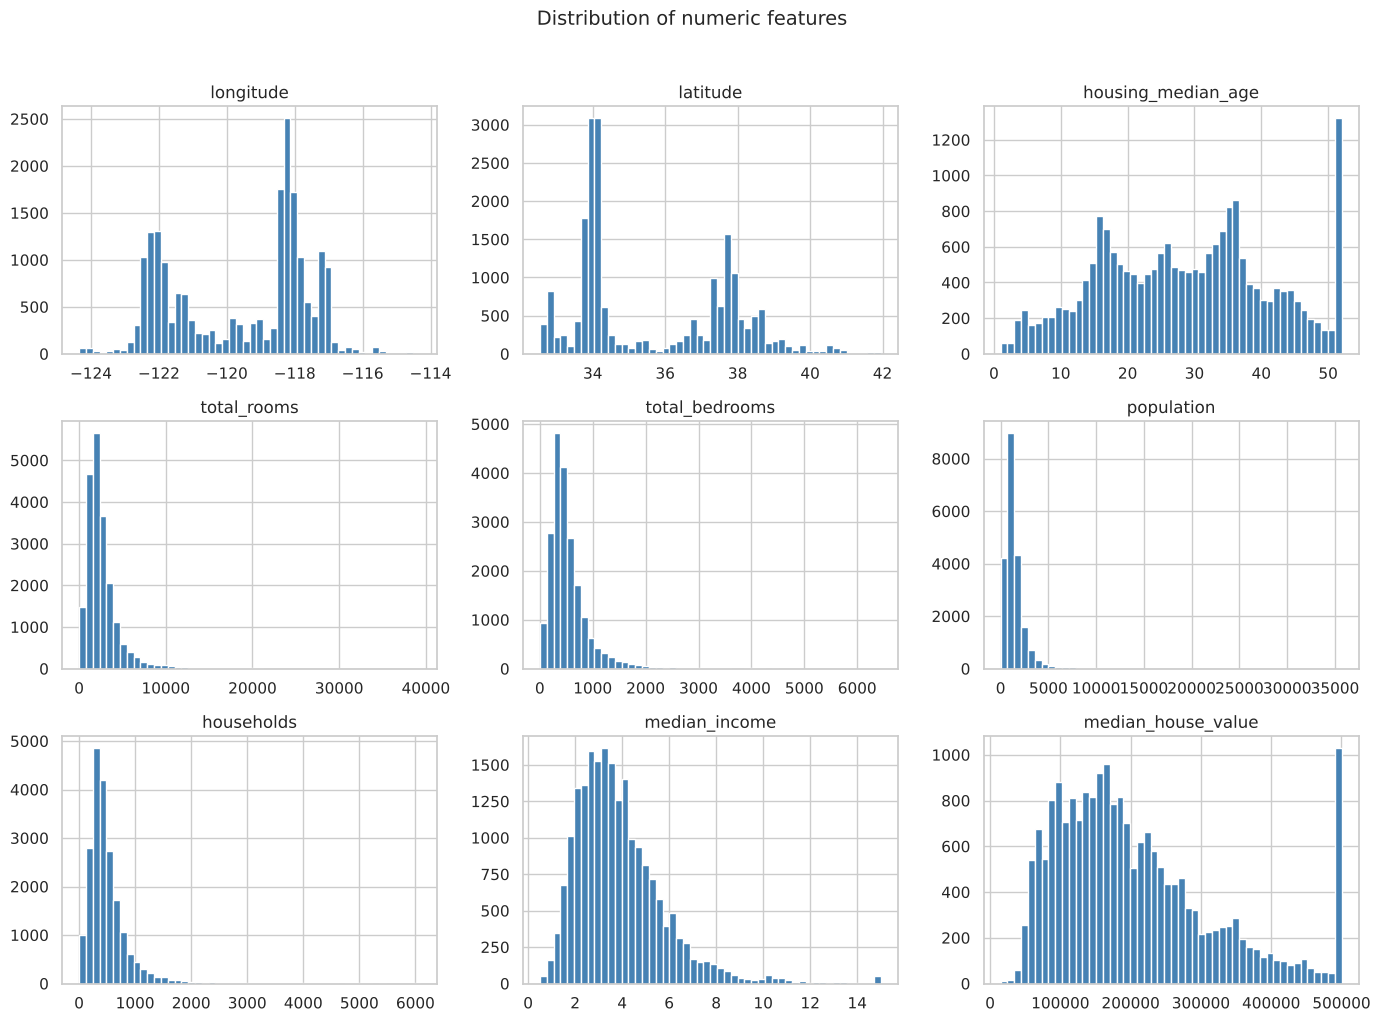

In [ ]:
num_cols = df.select_dtypes(include='number').columns
df[num_cols].hist(bins=50, figsize=(14, 10), color='steelblue', edgecolor='white')
plt.suptitle('Distribution of numeric features', y=1.02, fontsize=14)
plt.tight_layout()
plt.savefig(IMAGE_DIR / '01_histograms.png', dpi=120, bbox_inches='tight')
plt.show()

### 7.2 Longitude vs latitude, colored by house value
Plotting location gives you a rough map of California. Expensive areas should cluster along the coast.

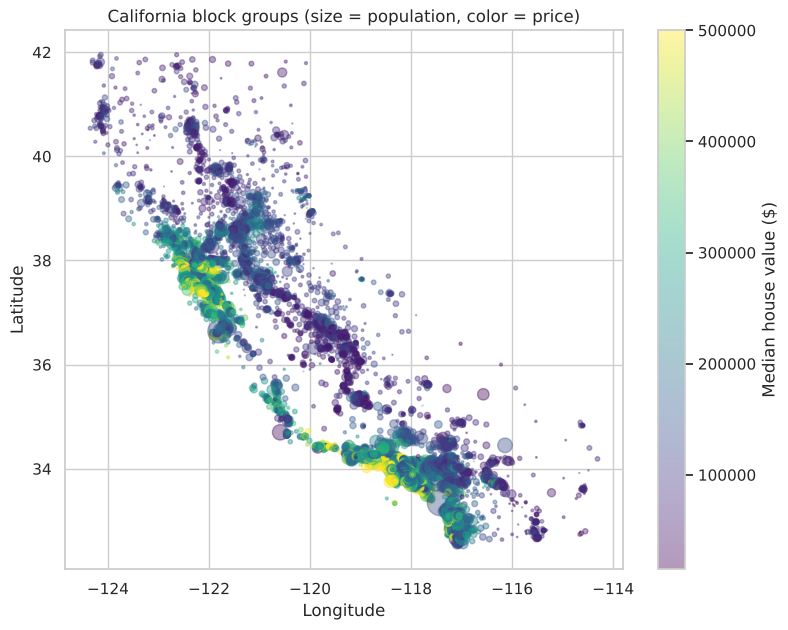

In [ ]:
plt.figure(figsize=(9, 7))
sc = plt.scatter(df['longitude'], df['latitude'], c=df['median_house_value'],
                 s=df['population'] / 100, alpha=0.4, cmap='viridis')
plt.colorbar(sc, label='Median house value ($)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('California block groups (size = population, color = price)')
plt.savefig(IMAGE_DIR / '02_map_scatter.png', dpi=120, bbox_inches='tight')
plt.show()

### 7.3 Box plots to spot outliers
Points far beyond the whiskers are outliers.

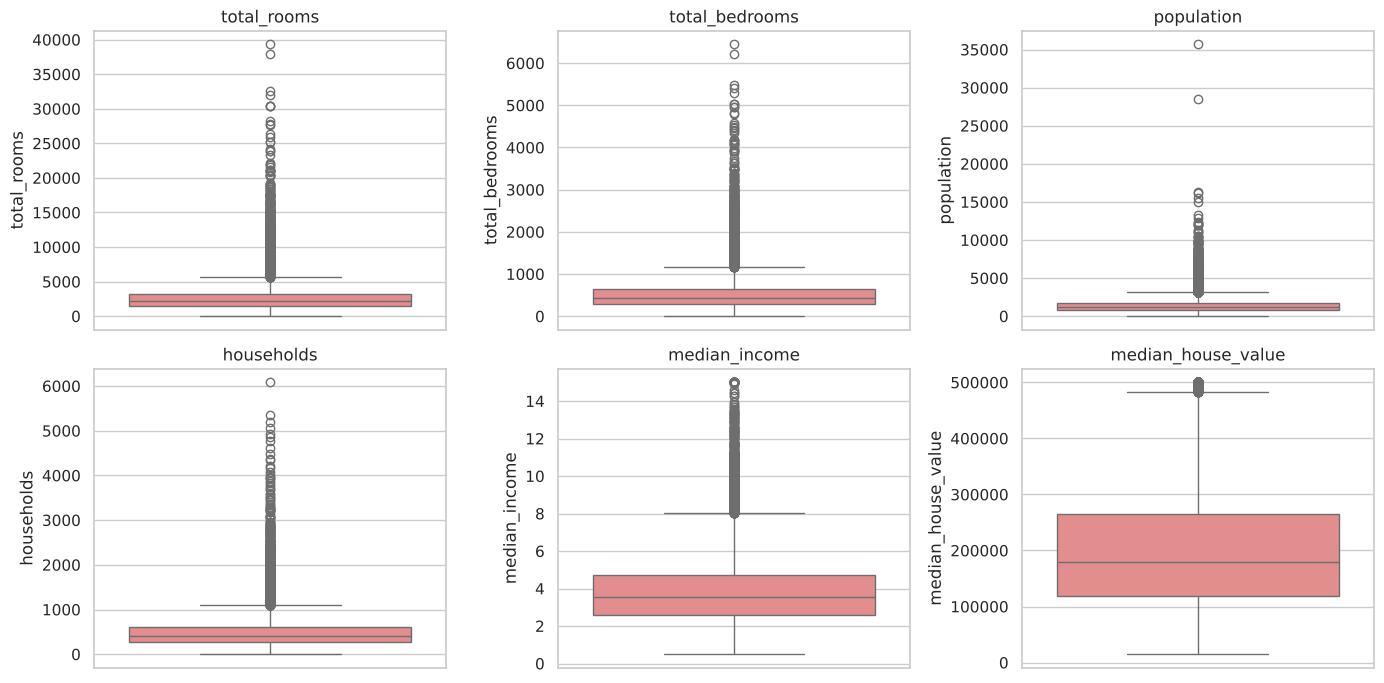

In [ ]:
box_cols = ['total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), box_cols):
    sns.boxplot(y=df[col], ax=ax, color='lightcoral')
    ax.set_title(col)
plt.tight_layout()
plt.savefig(IMAGE_DIR / '03_boxplots.png', dpi=120, bbox_inches='tight')
plt.show()

### 7.4 Correlation heatmap
Correlation ranges from -1 to +1. Values near +1 mean the two columns rise together.

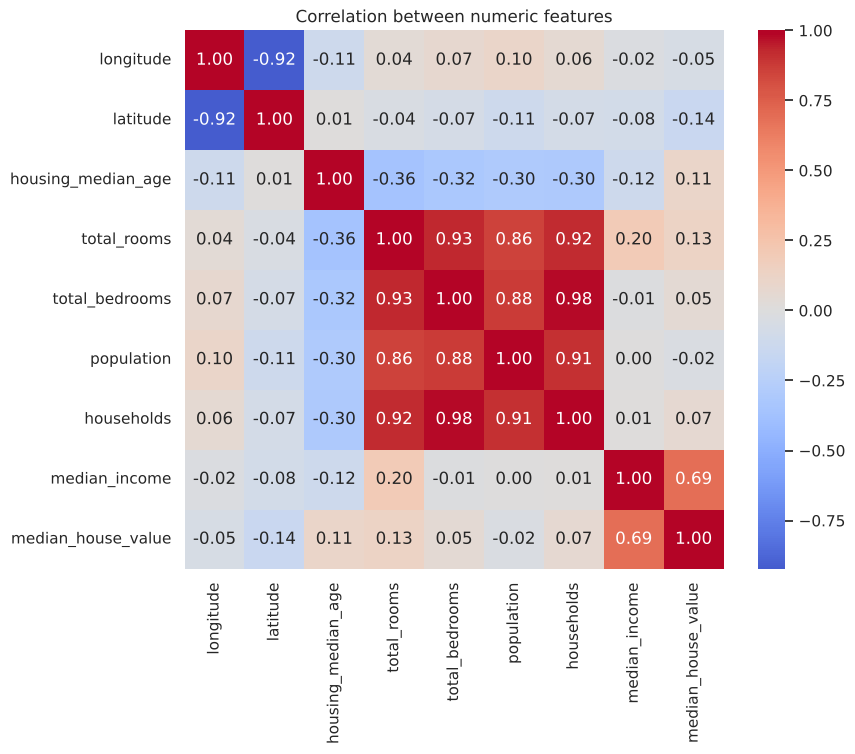

In [ ]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation between numeric features')
plt.savefig(IMAGE_DIR / '04_correlation_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
corr['median_house_value'].sort_values(ascending=False).round(3)

median_house_value    1.000
median_income         0.688
total_rooms           0.134
housing_median_age    0.106
households            0.066
total_bedrooms        0.050
population           -0.025
longitude            -0.046
latitude             -0.144
Name: median_house_value, dtype: float64

### 7.5 Average price per `ocean_proximity`

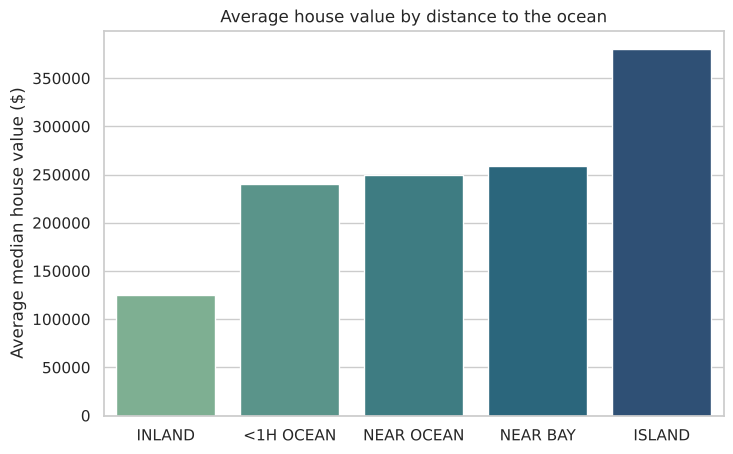

In [ ]:
avg_price = df.groupby('ocean_proximity')['median_house_value'].mean().sort_values()
plt.figure(figsize=(8, 5))
sns.barplot(x=avg_price.index, y=avg_price.values, hue=avg_price.index, palette='crest', legend=False)
plt.ylabel('Average median house value ($)')
plt.xlabel('')
plt.title('Average house value by distance to the ocean')
plt.savefig(IMAGE_DIR / '05_price_by_ocean.png', dpi=120, bbox_inches='tight')
plt.show()

## 8. Look for suspicious values
Some datasets cap values at a maximum. Let's check the price and house age columns.

In [ ]:
max_price = df['median_house_value'].max()
max_age = df['housing_median_age'].max()
print(f'Max price {max_price:,.0f} appears {(df.median_house_value == max_price).sum()} times')
print(f'Max age   {max_age:.0f} appears {(df.housing_median_age == max_age).sum()} times')

Max price 500,001 appears 965 times
Max age   52 appears 1273 times


## 9. Your observations

Fill in your own words below (the notes here are a starting point; check them against your output above):

1. **Missing data:** only `total_bedrooms` has missing values (207 rows, about 1%). There are no duplicate rows.
2. **Capped values:** the price column is capped at 500,001, and about 965 block groups sit exactly at that cap. House age is similarly capped at 52. The true values are unknown, so these rows can mislead a model.
3. **Skew and outliers:** rooms, bedrooms, population, and households are heavily right-skewed with extreme outliers.
4. **Strongest relationship:** `median_income` has by far the strongest correlation with price.
5. **Location matters:** `INLAND` blocks are much cheaper than coastal ones, and the map plot shows expensive areas hugging the coast. `ISLAND` has only 5 rows.

**Your turn:** add one observation of your own below.

## 10. Check your work

In [ ]:
assert df.shape == (20640, 10), 'Unexpected shape'
assert df['total_bedrooms'].isna().sum() == 207, 'Expected 207 missing total_bedrooms'
assert set(df['ocean_proximity'].unique()) == {'<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'NEAR BAY', 'ISLAND'}
assert (IMAGE_DIR / '04_correlation_heatmap.png').exists()
print('Notebook 01 checks passed. Next: 02_data_cleaning.ipynb')

Notebook 01 checks passed. Next: 02_data_cleaning.ipynb
